Dataset:
  StudyHours Attendance  Assignment Result
0        Low        Low  Incomplete   Fail
1        Low       High    Complete   Pass
2     Medium       High    Complete   Pass
3       High       High    Complete   Pass
4       High        Low  Incomplete   Fail
5     Medium       High    Complete   Pass
6       High        Low    Complete   Pass
7        Low        Low  Incomplete   Fail
8     Medium       High    Complete   Pass
9       High       High    Complete   Pass

Classification Rules:
IF Attendance = High THEN Result = Pass
IF StudyHours = High THEN Result = Pass
IF Assignment = Incomplete THEN Result = Fail

FOIL First-Order Rules:
result(X, pass) :- attendance(X, high).
result(X, pass) :- studyhours(X, high).
result(X, fail) :- assignment(X, incomplete).

FOIL Predictions:
StudyHours = High, Attendance = High, Assignment = Complete -> Result = Pass
StudyHours = Low, Attendance = Low, Assignment = Incomplete -> Result = Fail
StudyHours = High, Attendance = Low, Assignme

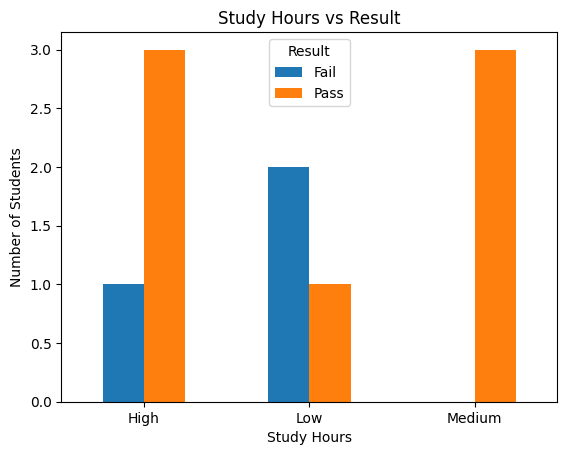

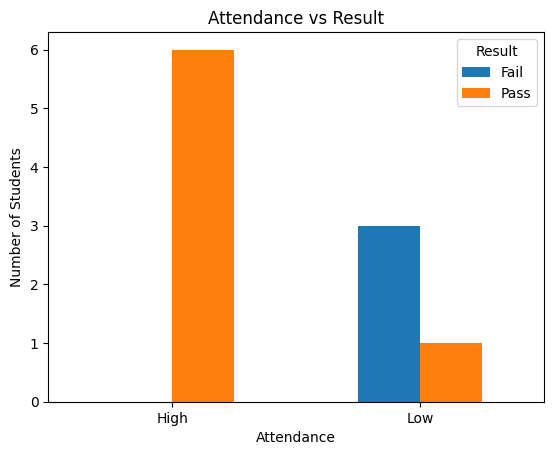

In [5]:

# Rule Learning using RIPPER-style Sequential Covering
# and FOIL First-Order Rules

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create Dataset

data = {
    'StudyHours': ['Low','Low','Medium','High','High',
                   'Medium','High','Low','Medium','High'],
    'Attendance': ['Low','High','High','High','Low',
                   'High','Low','Low','High','High'],
    'Assignment': ['Incomplete','Complete','Complete','Complete','Incomplete',
                   'Complete','Complete','Incomplete','Complete','Complete'],
    'Result': ['Fail','Pass','Pass','Pass','Fail',
               'Pass','Pass','Fail','Pass','Pass']
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# 2. Classification Rules

print("\nClassification Rules:")

rules = [
    ("Attendance", "High", "Pass"),
    ("StudyHours", "High", "Pass"),
    ("Assignment", "Incomplete", "Fail")
]

for attribute, value, result in rules:
    print(f"IF {attribute} = {value} THEN Result = {result}")

# 3. FOIL First-Order Rules

print("\nFOIL First-Order Rules:")

foil_rules = [
    "result(X, pass) :- attendance(X, high).",
    "result(X, pass) :- studyhours(X, high).",
    "result(X, fail) :- assignment(X, incomplete)."
]

for rule in foil_rules:
    print(rule)

# 4. Prediction using FOIL Rules

def foil_predict(studyhours, attendance, assignment):

    if attendance == "High":
        return "Pass"

    if studyhours == "High":
        return "Pass"

    if assignment == "Incomplete":
        return "Fail"

    return "Fail"

# Test examples

test_data = [
    ("High", "High", "Complete"),
    ("Low", "Low", "Incomplete"),
    ("High", "Low", "Complete"),
    ("Medium", "High", "Complete")
]

print("\nFOIL Predictions:")

for studyhours, attendance, assignment in test_data:
    prediction = foil_predict(
        studyhours, attendance, assignment
    )

    print(
        f"StudyHours = {studyhours}, "
        f"Attendance = {attendance}, "
        f"Assignment = {assignment} "
        f"-> Result = {prediction}"
    )

# 5. Graphs

pd.crosstab(
    df['StudyHours'],
    df['Result']
).plot(kind='bar')

plt.title("Study Hours vs Result")
plt.xlabel("Study Hours")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

pd.crosstab(
    df['Attendance'],
    df['Result']
).plot(kind='bar')

plt.title("Attendance vs Result")
plt.xlabel("Attendance")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()
